
# Analyse de la persistance temporelle des retards TGV

## Objectif

Cette analyse vise à déterminer si le taux de retard des TGV
observé au cours d'un mois présente une dépendance statistique
avec celui des mois précédents.

Nous étudions la série mensuelle du taux de trains arrivant
avec plus de 15 minutes de retard, de janvier 2018 à
septembre 2026.

L'analyse repose sur :

1. L'exploration de la série temporelle.
2. L'étude des autocorrélations (ACF et PACF).
3. Le test de stationnarité ADF.
4. L'estimation d'un modèle autorégressif AR(1).
5. Le diagnostic des résidus.
6. La comparaison des prévisions avec un modèle naïf.

Le modèle étudié s'écrit :

$$
R_t = \alpha + \phi R_{t-1} + \varepsilon_t
$$

où :

- $R_t$ est le taux de retard au mois $t$ ;
- $\alpha$ est la constante du modèle ;
- $\phi$ mesure la persistance temporelle ;
- $\varepsilon_t$ représente l'innovation aléatoire.


In [ ]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import pandas as pd

from projet_railinsight.data_processing import calculer_taux_mensuel

# Rendre le package du projet accessible depuis le notebook
PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))


# Charger les données SNCF
DATA_PATH = PROJECT_ROOT / "data/raw/regularite-mensuelle-tgv-aqst.csv"

df = pd.read_csv(DATA_PATH, sep=";")

# Construire la série temporelle mensuelle
mensuel = calculer_taux_mensuel(df)

# Extraire la série des taux de retard
serie = mensuel["taux_retard_15min"]

print(f"Nombre de mois : {len(serie)}")
print(f"Période : {serie.index.min():%Y-%m} à {serie.index.max():%Y-%m}")

serie.head()

Nombre de mois : 105
Période : 2018-01 à 2026-09


Date
2018-01-01     9.990284
2018-02-01    15.650445
2018-03-01     9.890237
2018-04-01    10.847472
2018-05-01    11.724340
Name: taux_retard_15min, dtype: float64

In [2]:
import plotly.express as px

fig = px.line(
    x=serie.index,
    y=serie.values,
    labels={
        "x": "Date",
        "y": "Taux de retard (%)",
    },
    title="Évolution mensuelle des retards TGV (2018–2026)",
)

fig.update_traces(
    mode="lines+markers",
    line={"width": 2},
    marker={"size": 4},
)

fig.update_layout(
    hovermode="x unified",
    xaxis_title="Année",
    yaxis_title="Trains en retard de plus de 15 min (%)",
    template="plotly_white",
)

fig.show()

In [3]:
import sys

import nbformat

print("Python utilisé :", sys.executable)
print("Version nbformat :", nbformat.__version__)

Python utilisé : /Users/ndaam/RailInsight-SNCF/.venv/bin/python
Version nbformat : 5.11.1


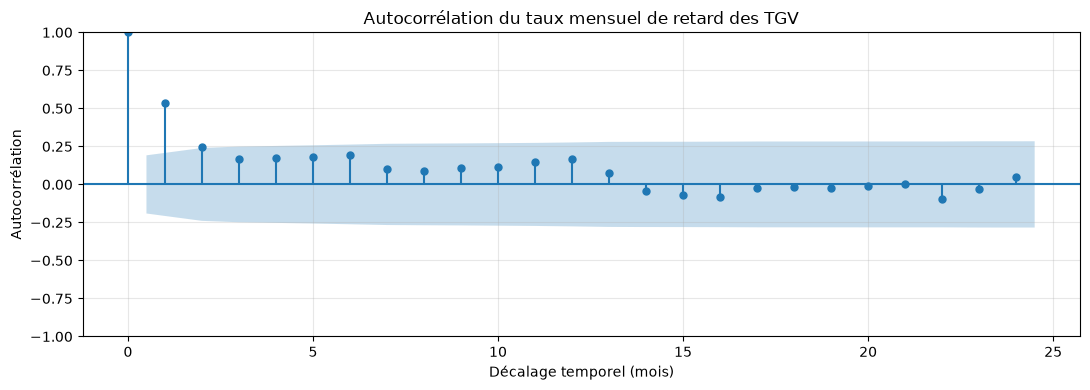

In [4]:
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

fig, ax = plt.subplots(figsize=(11, 4))

plot_acf(
    serie,
    lags=24,
    alpha=0.05,
    ax=ax,
)

ax.set_title("Autocorrélation du taux mensuel de retard des TGV")
ax.set_xlabel("Décalage temporel (mois)")
ax.set_ylabel("Autocorrélation")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

from projet_railinsight.data_processing import (
    calculer_taux_mensuel,
    charger_donnees_tgv,
)

# Chemin vers le fichier CSV SNCF
chemin = Path.cwd() / "data" / "raw" / "regularite-mensuelle-tgv-aqst.csv"

# Chargement des données
df = charger_donnees_tgv(chemin)

# Calcul des taux mensuels
mensuel = calculer_taux_mensuel(df)

print("Nombre de mois :", len(mensuel))
print("Première date :", mensuel.index.min())
print("Dernière date :", mensuel.index.max())
print(mensuel.head())

Nombre de mois : 105
Première date : 2018-01-01 00:00:00
Dernière date : 2026-09-01 00:00:00
            trains_retardes  trains_realises  taux_retard_15min
Date                                                           
2018-01-01             3496            34994           9.990284
2018-02-01             4959            31686          15.650445
2018-03-01             3415            34529           9.890237
2018-04-01             2647            24402          10.847472
2018-05-01             3195            27251          11.724340


In [6]:
import pandas as pd

# Calendrier mensuel attendu
dates_attendues = pd.date_range(
    start=mensuel.index.min(),
    end=mensuel.index.max(),
    freq="MS",
)

# Vérification des mois manquants
mois_manquants = dates_attendues.difference(mensuel.index)

# Vérification des taux manquants
taux_manquants = mensuel["taux_retard_15min"].isna().sum()

print("Mois manquants :", len(mois_manquants))
print("Taux manquants :", taux_manquants)
print("Dates dupliquées :", mensuel.index.duplicated().sum())

Mois manquants : 0
Taux manquants : 0
Dates dupliquées : 0


In [7]:
from projet_railinsight.persistence import estimer_ar1

# Série mensuelle déjà construite
serie = mensuel["taux_retard_15min"].asfreq("MS")

# Estimation du modèle AR(1)
resultat_ar1 = estimer_ar1(serie)

# Affichage des paramètres estimés
print(resultat_ar1.params)

const                   4.890981
taux_retard_15min.L1    0.534856
dtype: float64


In [8]:
# Série mensuelle des taux de retard
serie = mensuel["taux_retard_15min"].asfreq("MS")

# Séparation chronologique
train = serie.iloc[:-12]
test = serie.iloc[-12:]

print("Nombre de mois d'entraînement :", len(train))
print("Nombre de mois de test :", len(test))

print("Période d'entraînement :", train.index.min(), "à", train.index.max())
print("Période de test :", test.index.min(), "à", test.index.max())

Nombre de mois d'entraînement : 93
Nombre de mois de test : 12
Période d'entraînement : 2018-01-01 00:00:00 à 2025-09-01 00:00:00
Période de test : 2025-10-01 00:00:00 à 2026-09-01 00:00:00


In [9]:
from projet_railinsight.persistence import estimer_ar1, prevoir_naif

# 1. Estimer AR(1) uniquement sur les données d'entraînement
modele_train = estimer_ar1(train)

# 2. Récupérer les coefficients estimés
alpha = modele_train.params.iloc[0]
phi = modele_train.params.iloc[1]

# 3. Prévisions AR(1) à un mois glissant
valeurs_precedentes = serie.shift(1).loc[test.index]

pred_ar1 = alpha + phi * valeurs_precedentes

# 4. Prévisions du modèle naïf
pred_naif = prevoir_naif(serie).loc[test.index]

# 5. Comparer les premières prévisions
comparaison = pd.DataFrame(
    {
        "Observe": test,
        "AR1": pred_ar1,
        "Naif": pred_naif,
    }
)

print("Constante estimée :", alpha)
print("Coefficient AR(1) :", phi)
print(comparaison.head())

Constante estimée : 5.657490660912576
Coefficient AR(1) : 0.4374533218912457
              Observe        AR1       Naif
Date                                       
2025-10-01  12.405234  11.231924  12.742921
2025-11-01  13.869618  11.084202  12.405234
2025-12-01  12.807298  11.724801  13.869618
2026-01-01  17.434525  11.260086  12.807298
2026-02-01  11.892243  13.284282  17.434525


In [11]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

resultats = pd.DataFrame(
    {
        "MAE": [
            mean_absolute_error(test, pred_ar1),
            mean_absolute_error(test, pred_naif),
        ],
        "RMSE": [
            np.sqrt(mean_squared_error(test, pred_ar1)),
            np.sqrt(mean_squared_error(test, pred_naif)),
        ],
    },
    index=["AR(1)", "Naïf"],
)

print(resultats)

            MAE      RMSE
AR(1)  2.982962  3.646806
Naïf   2.974666  3.444180


In [13]:
from projet_railinsight.persistence import evaluer_previsions

print("AR(1) :", evaluer_previsions(test, pred_ar1))
print("Naïf :", evaluer_previsions(test, pred_naif))

AR(1) : {'MAE': 2.982962135382271, 'RMSE': 3.6468055310055507}
Naïf : {'MAE': 2.974666131676834, 'RMSE': 3.4441800038938895}


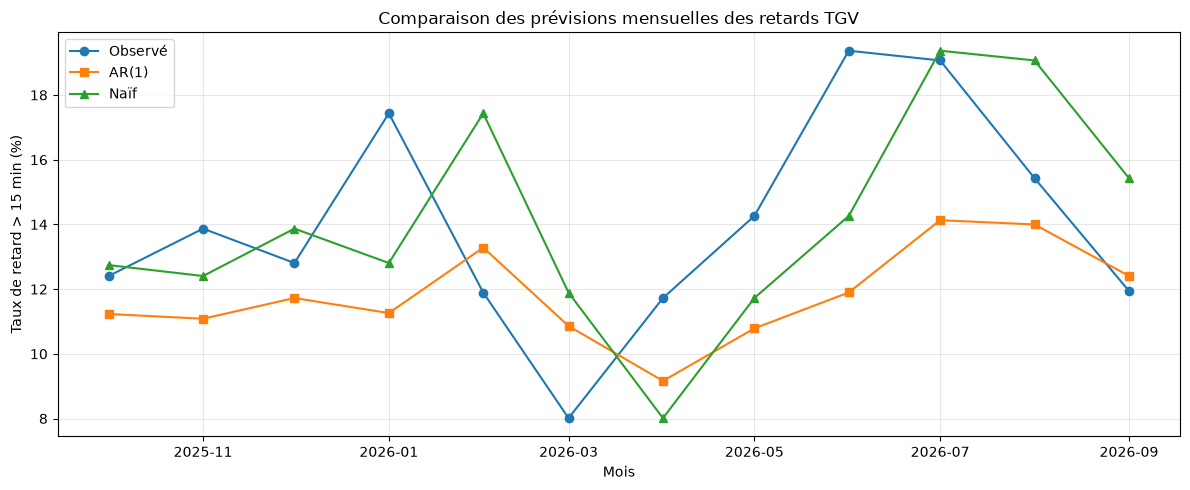

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(test.index, test, marker="o", label="Observé")
plt.plot(pred_ar1.index, pred_ar1, marker="s", label="AR(1)")
plt.plot(pred_naif.index, pred_naif, marker="^", label="Naïf")

plt.title("Comparaison des prévisions mensuelles des retards TGV")
plt.xlabel("Mois")
plt.ylabel("Taux de retard > 15 min (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()